Alcoholism and Religious Beliefs + Practices

In [1]:
import pandas as pd
import numpy as np
import plotnine as p9
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_stata("chrisu.DTA", convert_categoricals=False)

# 1 = any illegal drug use, 0 = none
df["drug_use"] = np.where(df["V79"].isna(), np.nan, (df["V79"] > 0).astype(int))

print(df["drug_use"].value_counts(dropna=False))   # expect 3221 zeros, 230 ones, 79 missing

drug_use
0.0    3221
1.0     230
NaN      79
Name: count, dtype: int64


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

df = pd.read_stata("chrisu.DTA", convert_categoricals=False)

df = df.rename(columns={
    "V25": "pray_freq", "V26": "table_grace", "V27": "pray_self",
    "V28": "pray_close", "V29": "pray_others", "V34": "attend_services",
    "V30": "god_close", "V39": "bible_inerrant", "V74": "drink_freq", "V75": "month_more_than_5_drinks_at_once", "V76": "week_more_than_5_drinks_at_once"
})

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. Load fresh data and rename
df = pd.read_stata("chrisu.DTA", convert_categoricals=False).copy()
df = df.rename(columns={
    # Section A: religious practices
    "V25": "pray_freq", "V26": "table_grace", "V27": "pray_self", 
    "V28": "pray_close", "V29": "pray_others", "V34": "attend_services",
    # Section B: religious beliefs
    "V30": "god_close", "V39": "bible_inerrant",
    # Outcome ingredient
    "V74": "drink_freq",
})
df["god_close"] = 6 - df["god_close"]       # reverse so higher = closer to God

# 2. Dependent variable: 1 = drinks more than 30 times a month (code 4), 0 = codes 0-3
df["more_than_30_drinks_monthly"] = np.where(df["drink_freq"].isna(), np.nan,
                                             (df["drink_freq"] == 4).astype(int))
print(df["more_than_30_drinks_monthly"].value_counts(dropna=False))

# 3. Independent variables
practices = ["pray_freq", "table_grace", "pray_self", "pray_close", "pray_others", "attend_services"]
beliefs = ["god_close", "bible_inerrant"]

# 4. One common sample
ca = df[["more_than_30_drinks_monthly"] + practices + beliefs].dropna().copy()
print("N =", len(ca), "| more_than_30_drinks_monthly = 1:", int(ca["more_than_30_drinks_monthly"].sum()))

# 5. Logit
m_alc = smf.logit("more_than_30_drinks_monthly ~ " + " + ".join(practices + beliefs), data=ca).fit()
print(m_alc.summary())

# Odds ratios are easier to explain than raw coefficients
print(np.exp(m_alc.params).round(3))

more_than_30_drinks_monthly
0.0    3302
1.0     146
NaN      82
Name: count, dtype: int64
N = 3004 | more_than_30_drinks_monthly = 1: 112
Optimization terminated successfully.
         Current function value: 0.151404
         Iterations 8
                                Logit Regression Results                               
Dep. Variable:     more_than_30_drinks_monthly   No. Observations:                 3004
Model:                                   Logit   Df Residuals:                     2995
Method:                                    MLE   Df Model:                            8
Date:                         Sat, 31 Oct 2026   Pseudo R-squ.:                 0.04905
Time:                                 14:14:38   Log-Likelihood:                -454.82
converged:                                True   LL-Null:                       -478.28
Covariance Type:                     nonrobust   LLR p-value:                 1.592e-07
                      coef    std err          z      P>

In [16]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

df = pd.read_stata("chrisu.DTA", convert_categoricals=False).copy()
df = df.rename(columns={
    "V25": "pray_freq", "V26": "table_grace", "V27": "pray_self",
    "V28": "pray_close", "V29": "pray_others", "V34": "attend_services",
    "V30": "god_close", "V39": "bible_inerrant",
    # ALCOHOLISM!!!
    "V74": "drink_freq", "V75": "month_more_than_5_drinks_at_once", "V76": "week_more_than_5_drinks_at_once",
})
df["god_close"] = 6 - df["god_close"]       # reverse so higher = closer to God

# Alcoholic = 1 if ANY of: drinks 30+ times a month, binged in past month, binged in past week
# V75/V76 codes: 1 = Yes, 2 = No, 3 = Uncertain (Uncertain counts as not yes)
outcome_items = ["drink_freq", "month_more_than_5_drinks_at_once", "week_more_than_5_drinks_at_once"]
any_missing = df[outcome_items].isna().any(axis=1)

alcoholic = ((df["drink_freq"] == 4) |
             (df["month_more_than_5_drinks_at_once"] == 1) |
             (df["week_more_than_5_drinks_at_once"] == 1))
df["alcoholic"] = np.where(any_missing, np.nan, alcoholic.astype(int))
print(df["alcoholic"].value_counts(dropna=False))

practices = ["pray_freq", "table_grace", "pray_self", "pray_close", "pray_others", "attend_services"]
beliefs = ["god_close", "bible_inerrant"]

ca = df[["alcoholic"] + practices + beliefs].dropna().copy()
print("N =", len(ca), "| alcoholic = 1:", int(ca["alcoholic"].sum()))

m_alc = smf.logit("alcoholic ~ " + " + ".join(practices + beliefs), data=ca).fit()
print(m_alc.summary())
print(np.exp(m_alc.params).round(3))

alcoholic
1.0    1681
0.0    1603
NaN     246
Name: count, dtype: int64
N = 2859 | alcoholic = 1: 1409
Optimization terminated successfully.
         Current function value: 0.644098
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:              alcoholic   No. Observations:                 2859
Model:                          Logit   Df Residuals:                     2850
Method:                           MLE   Df Model:                            8
Date:                Sat, 31 Oct 2026   Pseudo R-squ.:                 0.07063
Time:                        14:40:25   Log-Likelihood:                -1841.5
converged:                       True   LL-Null:                       -1981.4
Covariance Type:            nonrobust   LLR p-value:                 7.843e-56
                      coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------

In [12]:
practices = ["pray_freq", "table_grace", "pray_self", "pray_close", "pray_others", "attend_services"]
beliefs = ["god_close", "bible_inerrant"]

In [17]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
from stargazer.stargazer import Stargazer

df = pd.read_stata("chrisu.DTA", convert_categoricals=False).copy()
df = df.rename(columns={
    "V25": "pray_freq", "V26": "table_grace", "V27": "pray_self",
    "V28": "pray_close", "V29": "pray_others", "V34": "attend_services",
    "V30": "god_close", "V39": "bible_inerrant",
    "V74": "drink_freq", "V75": "month_more_than_5_drinks_at_once", "V76": "week_more_than_5_drinks_at_once",
})
df["god_close"] = 6 - df["god_close"]       # reverse so higher = closer to God

# separate binary outcomes (missing stays missing)
def flag(col, condition):
    return np.where(df[col].isna(), np.nan, condition.astype(int))

df["drinks_30_plus"] = flag("drink_freq", df["drink_freq"] == 4)                                     # more than 30 times a month
df["binge_month"]    = flag("month_more_than_5_drinks_at_once", df["month_more_than_5_drinks_at_once"] == 1)   # 1 = Yes
df["binge_week"]     = flag("week_more_than_5_drinks_at_once", df["week_more_than_5_drinks_at_once"] == 1)     # 1 = Yes
df["alcoholic"]      = np.where(df[["drinks_30_plus", "binge_month", "binge_week"]].isna().any(axis=1), np.nan,
                                df[["drinks_30_plus", "binge_month", "binge_week"]].max(axis=1))   # any of the three

outcomes = ["alcoholic", "drinks_30_plus", "binge_month", "binge_week"]
practices = ["pray_freq", "table_grace", "pray_self", "pray_close", "pray_others", "attend_services"]
beliefs = ["god_close", "bible_inerrant"]

# 1 common sample
ca = df[outcomes + practices + beliefs].dropna().copy()
print("N =", len(ca))
print(ca[outcomes].mean().round(3))             # share coded 1 for each outcome

# 1 logit per outcome, same predictors
models = [smf.logit(f"{o} ~ " + " + ".join(practices + beliefs), data=ca).fit(disp=0) for o in outcomes]

# table
sg = Stargazer(models)
sg.dependent_variable_name("Alcohol Use")
sg.custom_columns(["Any Heavy Drinking", "Drinks 30+ Times a Month", "Binged in Past Month", "Binged in Past Week"],
                  [1, 1, 1, 1])
sg.covariate_order(practices + beliefs + ["Intercept"])
sg.rename_covariates({
    "pray_freq": "PRACTICES: Praying Frequency", "table_grace": "PRACTICES: Saying Grace",
    "pray_self": "PRACTICES: Praying for Self", "pray_close": "PRACTICES: Praying for Close People",
    "pray_others": "PRACTICES: Praying for Others", "attend_services": "PRACTICES: Attending Services",
    "god_close": "BELIEFS: Closeness to God", "bible_inerrant": "BELIEFS: Bible Inerrancy",
    "Intercept": "Intercept",
})
sg.add_custom_notes(["Standard errors in parentheses."])
sg

N = 2859
alcoholic         0.493
drinks_30_plus    0.039
binge_month       0.484
binge_week        0.298
dtype: float64


In [20]:
# Items are on different scales (0-4, 0-5, 1-5), so standardise each one first (mean 0, SD 1)
z = (ca[practices + beliefs] - ca[practices + beliefs].mean()) / ca[practices + beliefs].std()

ca["practice_index"]    = z[practices].mean(axis=1)              # average of the 6 practices
ca["belief_index"]      = z[beliefs].mean(axis=1)                # average of the 2 beliefs
ca["religiosity_index"] = z[practices + beliefs].mean(axis=1)    # all 8 combined

# Cronbach's alpha: do the items measure one thing? (0.7+ is acceptable, 0.8+ is good)
def cronbach_alpha(items):
    k = items.shape[1]
    return k / (k - 1) * (1 - items.var().sum() / items.sum(axis=1).var())

print("alpha, practices:  ", round(cronbach_alpha(z[practices]), 3))
print("alpha, beliefs:    ", round(cronbach_alpha(z[beliefs]), 3))
print("alpha, all 8 items:", round(cronbach_alpha(z[practices + beliefs]), 3))
print("r(practice_index, belief_index) =", round(ca["practice_index"].corr(ca["belief_index"]), 2))

# Model A: one combined religiosity index, for each outcome
models_a = [smf.logit(f"{o} ~ religiosity_index", data=ca).fit(disp=0) for o in outcomes]
# Model B: practices and beliefs as two separate indices, for each outcome
models_b = [smf.logit(f"{o} ~ practice_index + belief_index", data=ca).fit(disp=0) for o in outcomes]

col_names = ["Any Heavy Drinking", "Drinks 30+ Times a Month", "Binged in Past Month", "Binged in Past Week"]

sg_a = Stargazer(models_a)
sg_a.dependent_variable_name("Alcohol Use")
sg_a.custom_columns(col_names, [1, 1, 1, 1])
sg_a.rename_covariates({"religiosity_index": "Religiosity Index (all 8 items)"})
sg_a.add_custom_notes(["Index = mean of standardised items. Standard errors in parentheses."])
display(sg_a)

sg_b = Stargazer(models_b)
sg_b.dependent_variable_name("Alcohol Use")
sg_b.custom_columns(col_names, [1, 1, 1, 1])
sg_b.rename_covariates({"practice_index": "PRACTICES Index (6 items)", "belief_index": "BELIEFS Index (2 items)"})
sg_b.add_custom_notes(["Index = mean of standardised items. Standard errors in parentheses."])
display(sg_b)

alpha, practices:   0.901
alpha, beliefs:     0.702
alpha, all 8 items: 0.914
r(practice_index, belief_index) = 0.74


In [21]:
# Make sure closeness to God is reversed (higher = closer to God), no matter how many times earlier cells ran
raw_v30 = pd.read_stata("chrisu.DTA", convert_categoricals=False, columns=["V30"])["V30"]
ca["god_close"] = 6 - raw_v30.loc[ca.index]          # V30: 1 = Very close ... 5 = No closeness -> now 5 = Very close

# Check: every item should correlate positively with praying frequency
check = ca[practices + beliefs].corr()["pray_freq"].round(2)
print(check)
assert (check > 0).all(), "An item points the wrong way, check its coding"

pray_freq          1.00
table_grace        0.60
pray_self          0.75
pray_close         0.71
pray_others        0.62
attend_services    0.68
god_close          0.70
bible_inerrant     0.56
Name: pray_freq, dtype: float64


In [18]:
m_alone = smf.logit("alcoholic ~ god_close", data=ca).fit(disp=0)          # no controls
m_full  = smf.logit("alcoholic ~ " + " + ".join(practices + beliefs), data=ca).fit(disp=0)   # controls for everything

sg2 = Stargazer([m_alone, m_full])
sg2.custom_columns(["Closeness Only", "With Practices & Beliefs"], [1, 1])
sg2.covariate_order(["god_close"] + practices + ["bible_inerrant", "Intercept"])
sg2

In [24]:
import plotnine as p9

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
outcome_labels = {"alcoholic": "Any heavy drinking", "drinks_30_plus": "Drinks 30+ times a month",
                  "binge_month": "Binged in past month", "binge_week": "Binged in past week"}
item_labels = {"pray_freq": "Praying frequency", "table_grace": "Saying grace", "pray_self": "Praying for self",
               "pray_close": "Praying for close people", "pray_others": "Praying for others",
               "attend_services": "Attending services", "god_close": "Closeness to God", "bible_inerrant": "Bible inerrancy"}
base_theme = (p9.theme_minimal(base_size=11)
              + p9.theme(panel_grid_minor=p9.element_blank(), panel_grid_major_y=p9.element_blank(),
                         plot_title=p9.element_text(weight="bold", ha="left"), axis_text=p9.element_text(color=MUTED)))

MARGINAL EFFECTS!!!! 

Average marginal effects, percentage points (full model)


outcome,Any heavy drinking,Drinks 30+ times a month,Binged in past month,Binged in past week
variable,,,,
Praying frequency,-4.3***,-1.4***,-3.9***,-3.6***
Saying grace,-5.6***,0.2,-6.0***,-3.1***
Praying for self,-2.5**,0.2,-2.8**,0.0
Praying for close people,2.4*,-0.2,2.6**,-0.1
Praying for others,0.3,0.5,0.2,1.7*
Attending services,-3.5***,-1.1***,-3.4***,-2.6***
Closeness to God,4.4***,1.1***,4.3***,2.8***
Bible inerrancy,-0.3,0.2,-0.0,-1.5**


Average marginal effects, percentage points (index model)


outcome,Any heavy drinking,Drinks 30+ times a month,Binged in past month,Binged in past week
variable,,,,
Practices index (per 1 SD),-17.1***,-2.8***,-17.2***,-10.0***
Beliefs index (per 1 SD),2.2,1.1*,2.7*,-0.7


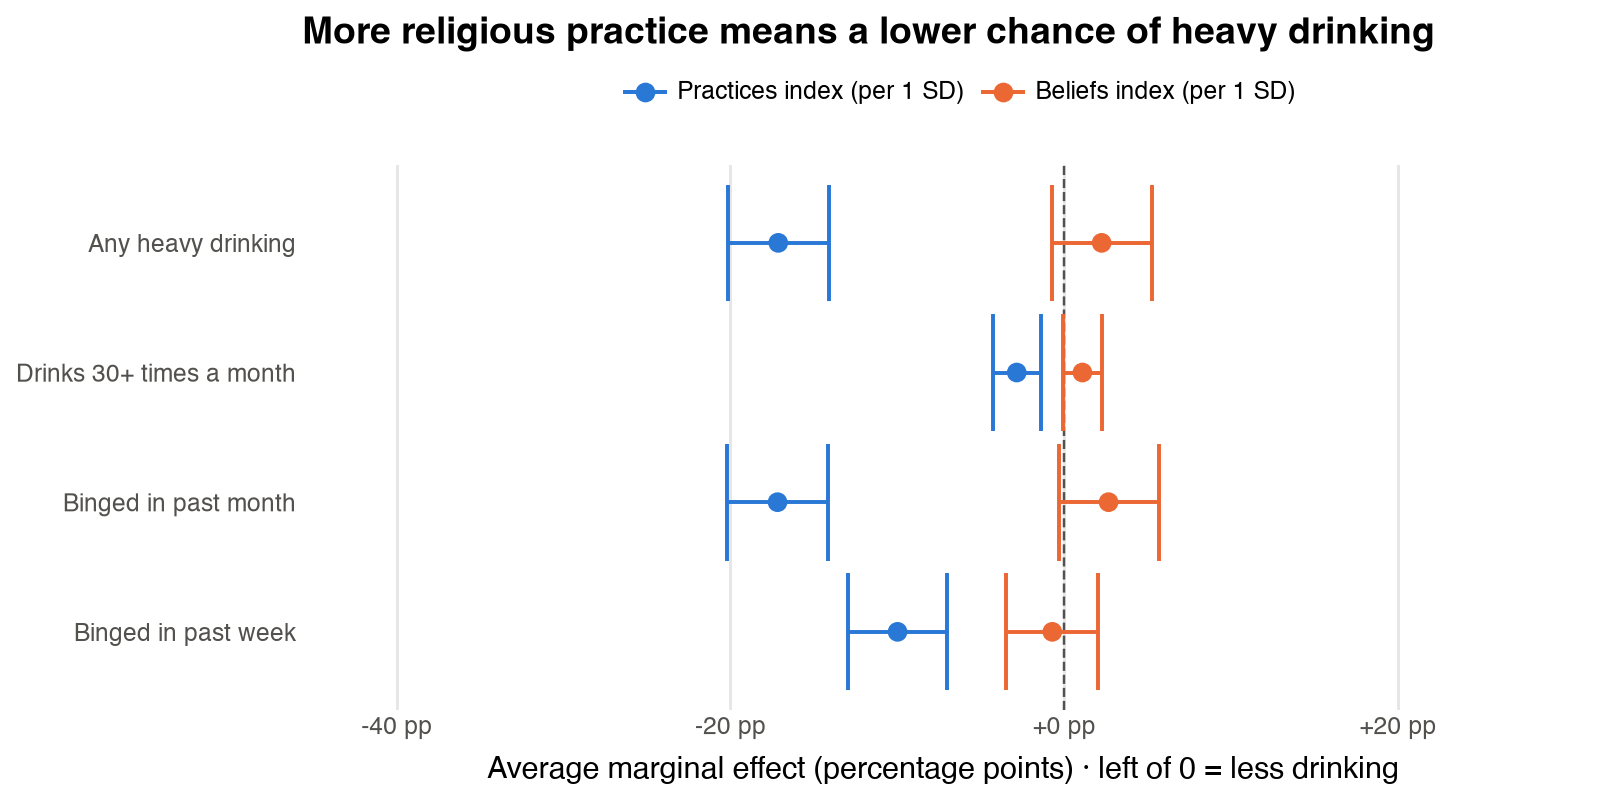

In [30]:
# Average marginal effects (AME): change in the PROBABILITY of the outcome for a 1-unit increase,
# averaged over every student in the sample
def ame_table(formula_rhs, names):
    rows = []
    for o in outcomes:
        m = smf.logit(f"{o} ~ {formula_rhs}", data=ca).fit(disp=0)
        me = m.get_margeff(at="overall").summary_frame()
        for v in me.index:
            rows.append({"outcome": outcome_labels[o], "variable": names.get(v, v), "AME": me.loc[v, "dy/dx"],
                         "lo": me.loc[v, "Conf. Int. Low"], "hi": me.loc[v, "Cont. Int. Hi."], "p": me.loc[v, "Pr(>|z|)"]})
    return pd.DataFrame(rows)

def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""

def to_wide(t):
    # Percentage points with stars, one column per outcome (like stargazer)
    t = t.assign(cell=(t["AME"] * 100).round(1).astype(str) + t["p"].map(stars))
    return t.pivot(index="variable", columns="outcome", values="cell")[list(outcome_labels.values())]

# Table 1: full 8-variable model
ame_full = ame_table(" + ".join(practices + beliefs), item_labels)
print("Average marginal effects, percentage points (full model)")
display(to_wide(ame_full).loc[[item_labels[v] for v in practices + beliefs]])

# Table 2: practices index vs beliefs index
index_names = {"practice_index": "Practices index (per 1 SD)", "belief_index": "Beliefs index (per 1 SD)"}
ame_idx = ame_table("practice_index + belief_index", index_names)
print("Average marginal effects, percentage points (index model)")
display(to_wide(ame_idx).loc[list(index_names.values())])

# Chart: marginal effects of the two indices
ame_idx["outcome"] = pd.Categorical(ame_idx["outcome"], categories=list(outcome_labels.values())[::-1])
ame_idx["variable"] = pd.Categorical(ame_idx["variable"], categories=list(index_names.values()))
chart_me = (p9.ggplot(ame_idx, p9.aes(x="AME", y="outcome", color="variable"))
            + p9.geom_vline(xintercept=0, color=MUTED, linetype="dashed")
            + p9.geom_errorbarh(p9.aes(xmin="lo", xmax="hi"), height=0, size=0.8, position=p9.position_dodge(width=0.5))
            + p9.geom_point(size=3, position=p9.position_dodge(width=0.5))
            + p9.scale_x_continuous(labels=lambda l: [f"{v*100:+.0f} pp" for v in l])
            + p9.scale_color_manual(values={index_names["practice_index"]: BLUE, index_names["belief_index"]: ORANGE})
            + p9.labs(title="More religious practice means a lower chance of heavy drinking",
                      x="Average marginal effect (percentage points) · left of 0 = less drinking", y="", color="")
            + base_theme + p9.theme(legend_position="top", figure_size=(8, 4)))
chart_me

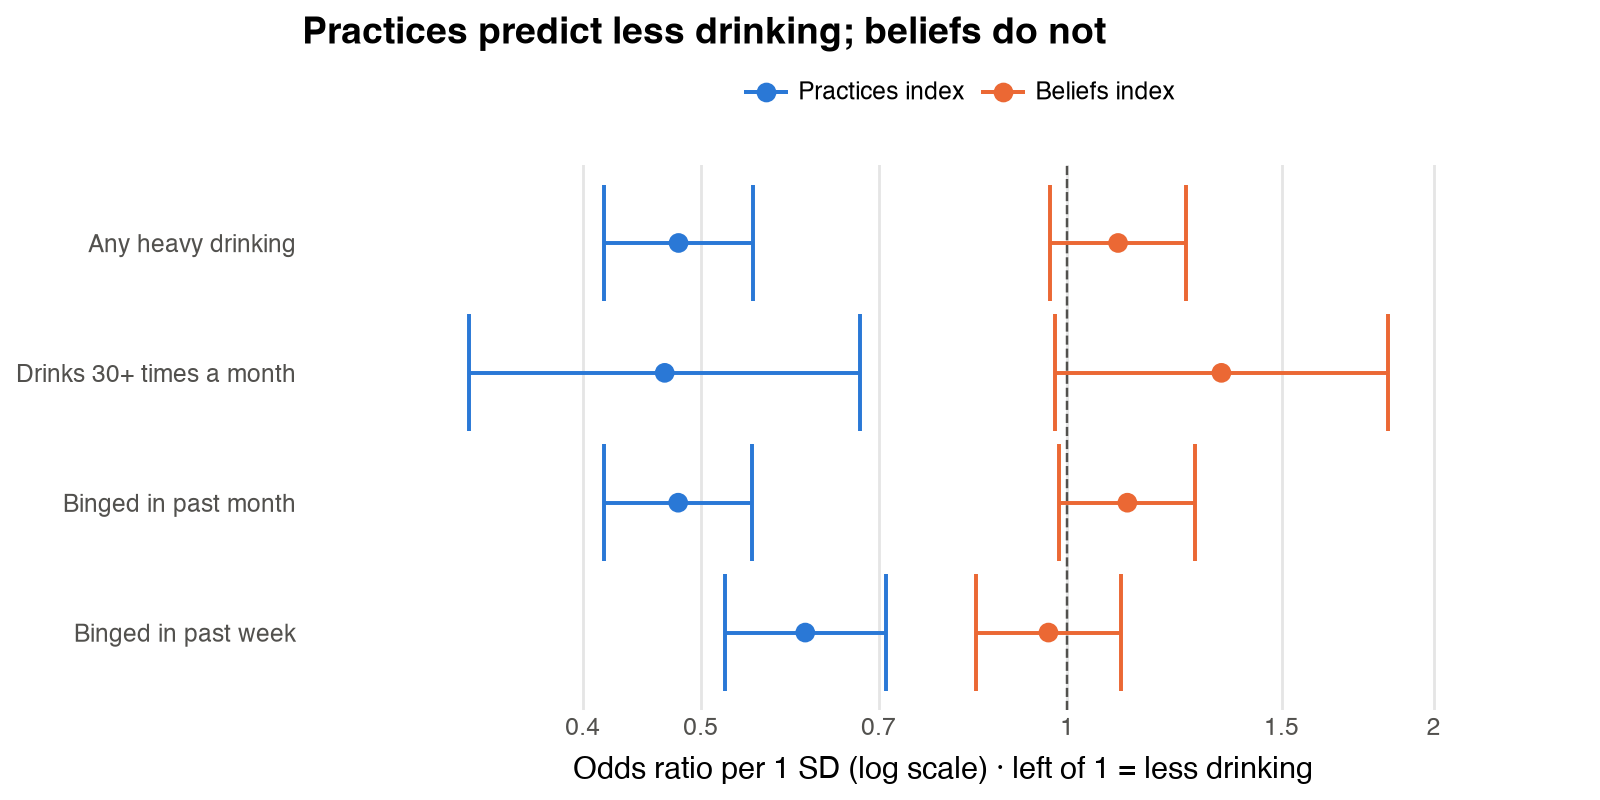

In [29]:
rows = []
for o in outcomes:
    m = smf.logit(f"{o} ~ practice_index + belief_index", data=ca).fit(disp=0)
    ci = m.conf_int()
    for v, lab in [("practice_index", "Practices index"), ("belief_index", "Beliefs index")]:
        rows.append({"outcome": outcome_labels[o], "predictor": lab, "OR": np.exp(m.params[v]),
                     "lo": np.exp(ci.loc[v, 0]), "hi": np.exp(ci.loc[v, 1])})
forest = pd.DataFrame(rows)
forest["outcome"] = pd.Categorical(forest["outcome"], categories=list(outcome_labels.values())[::-1])
forest["predictor"] = pd.Categorical(forest["predictor"], categories=["Practices index", "Beliefs index"])
chart1 = (p9.ggplot(forest, p9.aes(x="OR", y="outcome", color="predictor"))
          + p9.geom_vline(xintercept=1, color=MUTED, linetype="dashed")
          + p9.geom_errorbarh(p9.aes(xmin="lo", xmax="hi"), height=0, size=0.8, position=p9.position_dodge(width=0.5))
          + p9.geom_point(size=3, position=p9.position_dodge(width=0.5))
          + p9.scale_x_log10(breaks=[0.4, 0.5, 0.7, 1, 1.5, 2])
          + p9.scale_color_manual(values={"Practices index": BLUE, "Beliefs index": ORANGE})
          + p9.labs(title="Practices predict less drinking; beliefs do not",
                    x="Odds ratio per 1 SD (log scale) · left of 1 = less drinking", y="", color="")
          + base_theme + p9.theme(legend_position="top", figure_size=(8, 4)))
chart1

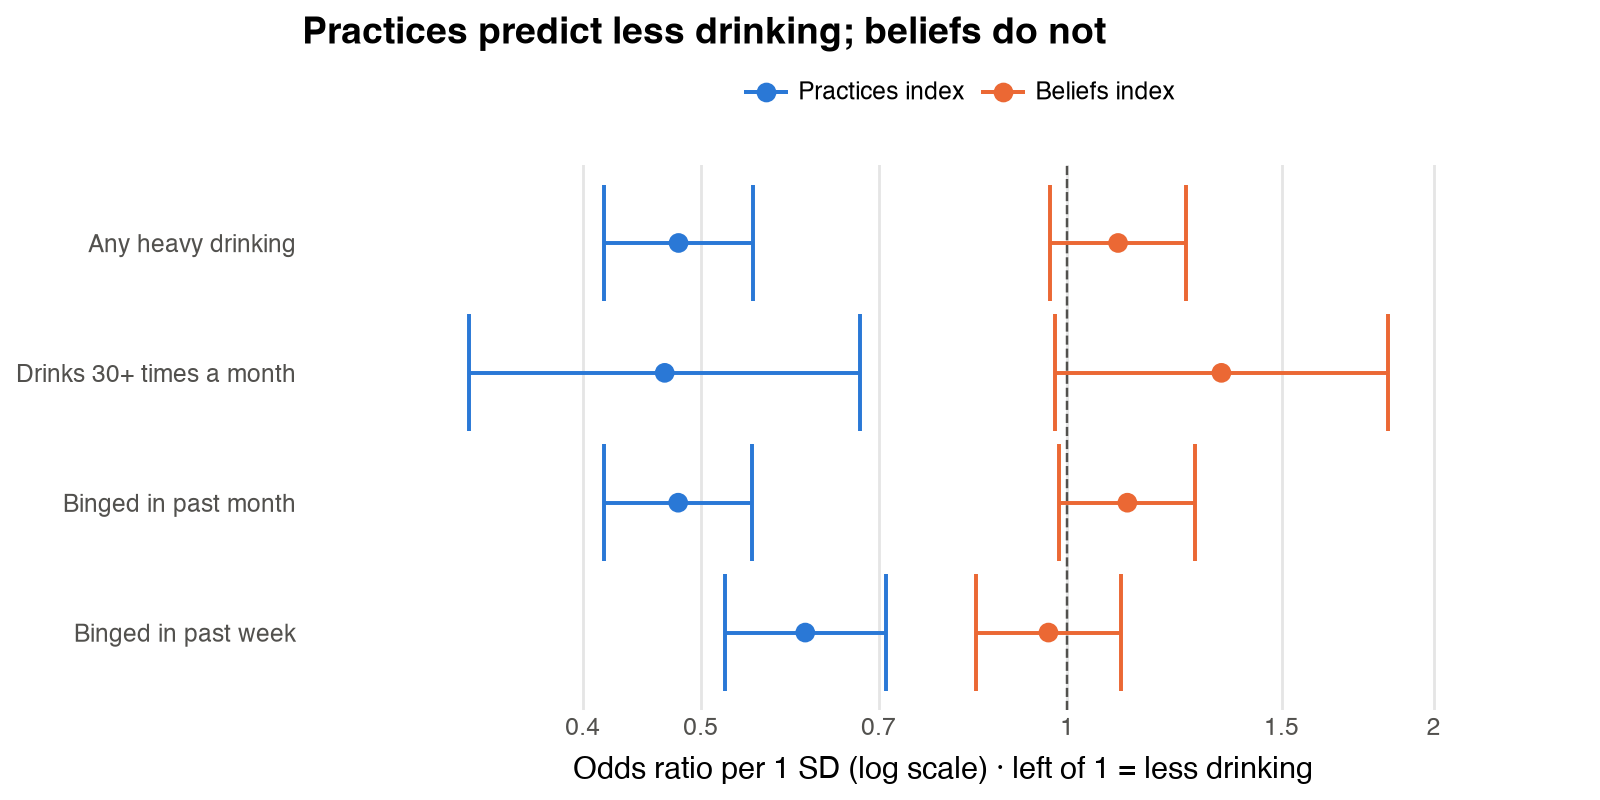

In [25]:
rows = []
for o in outcomes:
    m = smf.logit(f"{o} ~ practice_index + belief_index", data=ca).fit(disp=0)
    ci = m.conf_int()
    for v, lab in [("practice_index", "Practices index"), ("belief_index", "Beliefs index")]:
        rows.append({"outcome": outcome_labels[o], "predictor": lab, "OR": np.exp(m.params[v]),
                     "lo": np.exp(ci.loc[v, 0]), "hi": np.exp(ci.loc[v, 1])})
forest = pd.DataFrame(rows)
forest["outcome"] = pd.Categorical(forest["outcome"], categories=list(outcome_labels.values())[::-1])
forest["predictor"] = pd.Categorical(forest["predictor"], categories=["Practices index", "Beliefs index"])
chart1 = (p9.ggplot(forest, p9.aes(x="OR", y="outcome", color="predictor"))
          + p9.geom_vline(xintercept=1, color=MUTED, linetype="dashed")
          + p9.geom_errorbarh(p9.aes(xmin="lo", xmax="hi"), height=0, size=0.8, position=p9.position_dodge(width=0.5))
          + p9.geom_point(size=3, position=p9.position_dodge(width=0.5))
          + p9.scale_x_log10(breaks=[0.4, 0.5, 0.7, 1, 1.5, 2])
          + p9.scale_color_manual(values={"Practices index": BLUE, "Beliefs index": ORANGE})
          + p9.labs(title="Practices predict less drinking; beliefs do not",
                    x="Odds ratio per 1 SD (log scale) · left of 1 = less drinking", y="", color="")
          + base_theme + p9.theme(legend_position="top", figure_size=(8, 4)))
chart1

                pray_freq table_grace pray_self pray_close pray_others attend_services god_close bible_inerrant alcoholic
pray_freq          1.0***                                                                                                
table_grace       0.61***      1.0***                                                                                    
pray_self         0.76***     0.51***    1.0***                                                                          
pray_close        0.71***     0.49***   0.79***     1.0***                                                               
pray_others       0.67***     0.48***   0.67***    0.76***      1.0***                                                   
attend_services   0.68***      0.6***   0.58***    0.56***     0.52***          1.0***                                   
god_close         0.69***      0.5***    0.6***     0.6***     0.59***         0.56***    1.0***                         
bible_inerrant    0.56**

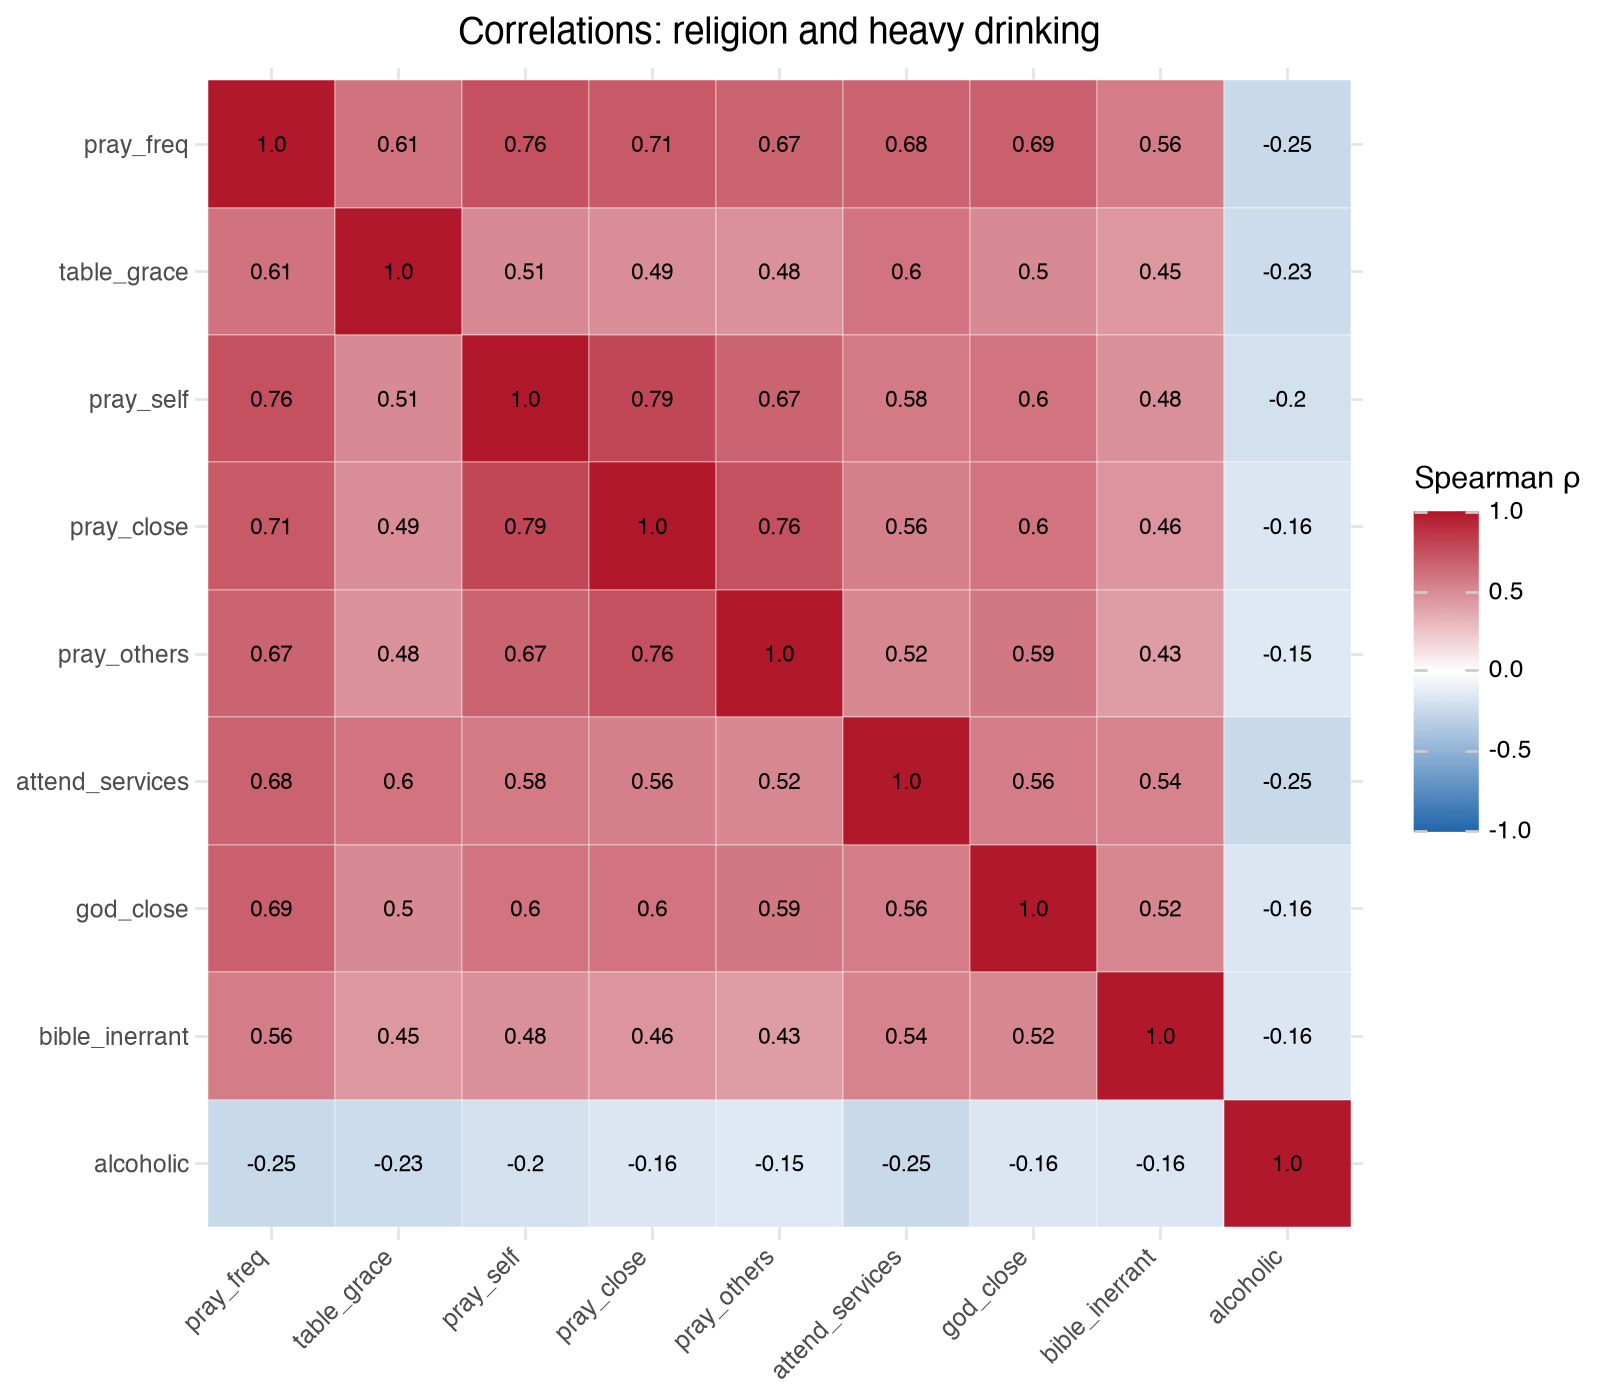

In [19]:
from scipy.stats import spearmanr
import plotnine as p9

cols = practices + beliefs + ["alcoholic"]

# Spearman correlation (rho) and p-values for every pair
rho, p = spearmanr(ca[cols])
rho = pd.DataFrame(rho, index=cols, columns=cols)
p = pd.DataFrame(p, index=cols, columns=cols)

# Table with stars, same convention as stargazer
stars = p.map(lambda x: "***" if x < 0.01 else "**" if x < 0.05 else "*" if x < 0.1 else "")
table = rho.round(2).astype(str) + stars
table = table.where(np.tril(np.ones(rho.shape, dtype=bool)), "")   # lower triangle only
print(table.to_string())

# Heatmap
long = rho.reset_index().melt(id_vars="index", var_name="var2", value_name="rho").rename(columns={"index": "var1"})
long["var1"] = pd.Categorical(long["var1"], categories=cols)
long["var2"] = pd.Categorical(long["var2"], categories=cols[::-1])
heat = (p9.ggplot(long, p9.aes("var1", "var2", fill="rho"))
        + p9.geom_tile(color="white")
        + p9.geom_text(p9.aes(label="rho.round(2)"), size=8)
        + p9.scale_fill_gradient2(low="#2166ac", mid="white", high="#b2182b", midpoint=0, limits=(-1, 1))
        + p9.labs(x="", y="", fill="Spearman ρ", title="Correlations: religion and heavy drinking")
        + p9.theme_minimal()
        + p9.theme(axis_text_x=p9.element_text(rotation=45, ha="right"), figure_size=(8, 7)))
heat

Controls: Gender, Race, Age, Parents' Education

In [31]:
# Control variables
df["female"]    = np.where(df["V3"].isna(), np.nan, (df["V3"] == 2).astype(int))     # V3: 1 = Male, 2 = Female
df["age"]       = df["V1"]                                                            # V1: 1 = 18 or under ... 6 = 23 or older
df["white"]     = np.where(df["V2"].isna(), np.nan, (df["V2"] == 1).astype(int))     # V2: 1 = White, 2-5 = other groups
df["mother_edu"] = df["V5"].where(df["V5"].between(1, 8))                             # V5: 1-8 scale; code 9 has no label, so set to missing
# University: asked in two versions of the survey (V91 or V92), combined into one variable
df["university"] = np.where(df["V91"].notna(), "A" + df["V91"].astype("Int64").astype(str),
                            np.where(df["V92"].notna(), "B" + df["V92"].astype("Int64").astype(str), np.nan))
df.loc[df["university"].isin(["nan", "A<NA>", "B<NA>"]), "university"] = np.nan

controls = ["female", "age", "white", "mother_edu"]

# One common sample: everyone with all outcomes, religion items AND controls
cc = df[outcomes + practices + beliefs + controls + ["university"]].dropna().copy()
print("N =", len(cc))

z = (cc[practices + beliefs] - cc[practices + beliefs].mean()) / cc[practices + beliefs].std()
cc["practice_index"] = z[practices].mean(axis=1)
cc["belief_index"]   = z[beliefs].mean(axis=1)

rhs_no_ctrl = "practice_index + belief_index"
rhs_ctrl    = "practice_index + belief_index + " + " + ".join(controls)
rhs_ctrl_uni = rhs_ctrl + " + C(university)"                # adds a separate intercept for each university

N = 2771


In [32]:
from statsmodels.imputation.mice import MICEData
from scipy.stats import norm

items = practices + beliefs

def index_ame(data, rhs_extra=""):
    """Build the two indices on this data, fit the logit, return AMEs (pp) and their SEs for both indices."""
    d = data.copy()
    z = (d[items] - d[items].mean()) / d[items].std()
    d["practice_index"] = z[practices].mean(axis=1)
    d["belief_index"]   = z[beliefs].mean(axis=1)
    m = smf.logit(f"alcoholic ~ practice_index + belief_index + {' + '.join(controls)} + C(university){rhs_extra}", data=d).fit(disp=0)
    me = m.get_margeff(at="overall").summary_frame().loc[["practice_index", "belief_index"]]
    return me["dy/dx"] * 100, me["Std. Err."] * 100, len(d)

# Keep everyone whose drinking outcome is known (we don't make up the outcome itself)
base = df[df["alcoholic"].notna()][["alcoholic"] + items + controls + ["university"]].copy()

# --- Approach 1: complete cases (what we have been doing) ---
est_cc, se_cc, n_cc = index_ame(base.dropna())

# --- Approach 2: missing-indicator ---
# Fill missing attendance with 0 ("Never") and add a flag, since most who skipped it never pray
mi_data = base.copy()
mi_data["attend_missing"] = mi_data["attend_services"].isna().astype(int)
mi_data["attend_services"] = mi_data["attend_services"].fillna(0)
est_ind, se_ind, n_ind = index_ame(mi_data.dropna(), " + attend_missing")

# --- Approach 3: multiple imputation (MICE) ---
# Fill each missing answer using the student's other answers, 20 times, then average the results (Rubin's rules)
imp = base[["alcoholic"] + items + controls].copy()
uni_dummies = pd.get_dummies(base["university"], prefix="uni", drop_first=True).astype(float)
imp = pd.concat([imp, uni_dummies], axis=1)

mice = MICEData(imp)                       # predictive mean matching: only fills in values that real students gave
ests, ses = [], []
for i in range(20):
    mice.update_all(5)
    filled = mice.data.copy()
    filled["university"] = base["university"].values
    e, s, n_mi = index_ame(filled)
    ests.append(e); ses.append(s)
ests, ses = pd.DataFrame(ests), pd.DataFrame(ses)
est_mi = ests.mean()
se_mi = np.sqrt((ses ** 2).mean() + (1 + 1 / len(ests)) * ests.var())     # Rubin's rules

def fmt(e, s):
    p = 2 * (1 - norm.cdf(abs(e / s)))
    return f"{e:.1f}" + ("***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else "")

compare = pd.DataFrame({
    "Complete cases":      [fmt(est_cc[v], se_cc[v]) for v in est_cc.index] + [n_cc],
    "Missing indicator":   [fmt(est_ind[v], se_ind[v]) for v in est_ind.index] + [n_ind],
    "Multiple imputation": [fmt(est_mi[v], se_mi[v]) for v in est_mi.index] + [n_mi],
}, index=["Practices index (pp per 1 SD)", "Beliefs index (pp per 1 SD)", "N"])
print("Any heavy drinking: average marginal effects, with demographic and university controls")
display(compare)

Any heavy drinking: average marginal effects, with demographic and university controls


,Complete cases,Missing indicator,Multiple imputation
Practices index (pp per 1 SD),-11.5***,-11.9***,-11.6***
Beliefs index (pp per 1 SD),0.6,1.4,1.9
N,2771,3095,3284


In [33]:
from stargazer.stargazer import Stargazer, LineLocation

# Three models for "any heavy drinking": no controls -> demographics -> demographics + university
models_c = [smf.logit(f"alcoholic ~ {rhs}", data=cc).fit(disp=0) for rhs in [rhs_no_ctrl, rhs_ctrl, rhs_ctrl_uni]]

sg_c = Stargazer(models_c)
sg_c.dependent_variable_name("Any Heavy Drinking")
sg_c.custom_columns(["No Controls", "+ Demographics", "+ University"], [1, 1, 1])
sg_c.covariate_order(["practice_index", "belief_index"] + controls + ["Intercept"])   # hides the university dummies
sg_c.rename_covariates({"practice_index": "PRACTICES Index (per 1 SD)", "belief_index": "BELIEFS Index (per 1 SD)",
                        "female": "Female", "age": "Age", "white": "White", "mother_edu": "Mother's Education"})
sg_c.add_line("University fixed effects", ["No", "No", "Yes"], LineLocation.FOOTER_TOP)
sg_c.add_custom_notes(["Standard errors in parentheses. Same sample in all models."])
display(sg_c)

# Average marginal effects (percentage points), same three models
names = {"practice_index": "Practices index (per 1 SD)", "belief_index": "Beliefs index (per 1 SD)",
         "female": "Female", "age": "Age", "white": "White", "mother_edu": "Mother's education"}
cols = {}
for label, m in zip(["No Controls", "+ Demographics", "+ University"], models_c):
    me = m.get_margeff(at="overall").summary_frame()
    me = me.loc[[v for v in names if v in me.index]]
    cols[label] = (me["dy/dx"] * 100).round(1).astype(str) + me["Pr(>|z|)"].map(lambda p: "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else "")
ame_c = pd.DataFrame(cols).reindex(list(names)).rename(index=names).fillna("")
print("Average marginal effects, percentage points (any heavy drinking)")
display(ame_c)

Average marginal effects, percentage points (any heavy drinking)


,No Controls,+ Demographics,+ University
Practices index (per 1 SD),-17.4***,-15.8***,-11.5***
Beliefs index (per 1 SD),2.5,2.4,0.6
Female,,-12.2***,-10.7***
Age,,2.6***,2.7***
White,,14.0***,12.8***
Mother's education,,0.0,0.1


In [34]:
from statsmodels.imputation.mice import MICEData
from scipy.stats import norm
from stargazer.stargazer import Stargazer, LineLocation

items = practices + beliefs

def add_indices(data):
    """Standardise the 8 religion items and average them into the two indices."""
    d = data.copy()
    z = (d[items] - d[items].mean()) / d[items].std()
    d["practice_index"] = z[practices].mean(axis=1)
    d["belief_index"]   = z[beliefs].mean(axis=1)
    return d

def pool(fits):
    """Combine logits fitted on each imputed dataset into one result (Rubin's rules), in a form Stargazer can read."""
    params = pd.DataFrame([f.params for f in fits])
    bse    = pd.DataFrame([f.bse for f in fits])
    est = params.mean()
    se  = np.sqrt((bse ** 2).mean() + (1 + 1 / len(fits)) * params.var())
    pooled = fits[0]                                   # reuse one fit as a container, then overwrite its numbers
    r = pooled._results
    r.params = est.values
    r._cache["bse"] = se.values
    z = (est / se).values
    r._cache["tvalues"] = z
    r._cache["pvalues"] = 2 * (1 - norm.cdf(np.abs(z)))
    r._cache["prsquared"] = np.mean([f.prsquared for f in fits])
    return pooled

rhs = "practice_index + belief_index + " + " + ".join(controls) + " + C(university)"

# Everyone whose drinking outcome is known (we don't make up the outcome itself)
base = df[df["alcoholic"].notna()][["alcoholic"] + items + controls + ["university"]].copy()

# Model 1: complete cases
m_cc = smf.logit(f"alcoholic ~ {rhs}", data=add_indices(base.dropna())).fit(disp=0)

# Model 2: missing indicator (missing attendance -> 0 "Never", plus a flag)
ind = base.copy()
ind["attend_missing"] = ind["attend_services"].isna().astype(int)
ind["attend_services"] = ind["attend_services"].fillna(0)
m_ind = smf.logit(f"alcoholic ~ {rhs} + attend_missing", data=add_indices(ind.dropna())).fit(disp=0)

# Model 3: multiple imputation (20 imputed datasets, pooled)
imp = base[["alcoholic"] + items + controls].copy()
imp = pd.concat([imp, pd.get_dummies(base["university"], prefix="uni", drop_first=True).astype(float)], axis=1)
mice = MICEData(imp)                                   # predictive mean matching: only fills in values real students gave
fits = []
for i in range(20):
    mice.update_all(5)
    filled = mice.data.copy()
    filled["university"] = base["university"].values
    fits.append(smf.logit(f"alcoholic ~ {rhs}", data=add_indices(filled)).fit(disp=0))
m_mi = pool(fits)

# Table
sg_miss = Stargazer([m_cc, m_ind, m_mi])
sg_miss.dependent_variable_name("Any Heavy Drinking")
sg_miss.custom_columns(["Complete Cases", "Missing Indicator", "Multiple Imputation"], [1, 1, 1])
sg_miss.covariate_order(["practice_index", "belief_index"] + controls + ["attend_missing", "Intercept"])   # hides university dummies
sg_miss.rename_covariates({"practice_index": "PRACTICES Index (per 1 SD)", "belief_index": "BELIEFS Index (per 1 SD)",
                           "female": "Female", "age": "Age", "white": "White", "mother_edu": "Mother's Education",
                           "attend_missing": "Skipped attendance question"})
sg_miss.add_line("University fixed effects", ["Yes", "Yes", "Yes"], LineLocation.FOOTER_TOP)
sg_miss.add_custom_notes(["Standard errors in parentheses.",
                          "Multiple imputation: 20 datasets (MICE), pooled with Rubin's rules; Pseudo R2 is the average."])
display(sg_miss)

In [35]:
from stargazer.stargazer import Stargazer, LineLocation

# Same 8 religion items as before, now with demographic controls and university fixed effects
rhs_full = " + ".join(practices + beliefs + controls) + " + C(university)"
models_ctrl = [smf.logit(f"{o} ~ {rhs_full}", data=cc).fit(disp=0) for o in outcomes]

sg_ctrl = Stargazer(models_ctrl)
sg_ctrl.dependent_variable_name("Alcohol Use")
sg_ctrl.custom_columns(["Any Heavy Drinking", "Drinks 30+ Times a Month", "Binged in Past Month", "Binged in Past Week"],
                       [1, 1, 1, 1])
sg_ctrl.covariate_order(practices + beliefs + controls + ["Intercept"])     # hides the university dummies
sg_ctrl.rename_covariates({
    "pray_freq": "PRACTICES: Praying Frequency", "table_grace": "PRACTICES: Saying Grace",
    "pray_self": "PRACTICES: Praying for Self", "pray_close": "PRACTICES: Praying for Close People",
    "pray_others": "PRACTICES: Praying for Others", "attend_services": "PRACTICES: Attending Services",
    "god_close": "BELIEFS: Closeness to God", "bible_inerrant": "BELIEFS: Bible Inerrancy",
    "female": "CONTROLS: Female", "age": "CONTROLS: Age", "white": "CONTROLS: White",
    "mother_edu": "CONTROLS: Mother's Education", "Intercept": "Intercept",
})
sg_ctrl.add_line("University fixed effects", ["Yes", "Yes", "Yes", "Yes"], LineLocation.FOOTER_TOP)
sg_ctrl.add_custom_notes(["Standard errors in parentheses."])
display(sg_ctrl)

/Users/ricep0et/venvs/hs4002/lib/python3.14/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals


In [37]:
from stargazer.stargazer import Stargazer, LineLocation

rhs_none = " + ".join(practices + beliefs)
rhs_ctrl = " + ".join(practices + beliefs + controls) + " + C(university)"

# For each outcome: one model without controls, then one with (same students in both)
pairs = []
for o in outcomes:
    pairs.append(smf.logit(f"{o} ~ {rhs_none}", data=cc).fit(disp=0))
    pairs.append(smf.logit(f"{o} ~ {rhs_ctrl}", data=cc).fit(disp=0))

sg_cmp = Stargazer(pairs)
sg_cmp.dependent_variable_name("Alcohol Use")
sg_cmp.custom_columns(["Any Heavy Drinking", "Drinks 30+ Times a Month", "Binged in Past Month", "Binged in Past Week"],
                      [2, 2, 2, 2])
sg_cmp.covariate_order(practices + beliefs + controls)                       # hides intercept and university dummies
sg_cmp.rename_covariates({
    "pray_freq": "PRACTICES: Praying Frequency", "table_grace": "PRACTICES: Saying Grace",
    "pray_self": "PRACTICES: Praying for Self", "pray_close": "PRACTICES: Praying for Close People",
    "pray_others": "PRACTICES: Praying for Others", "attend_services": "PRACTICES: Attending Services",
    "god_close": "BELIEFS: Closeness to God", "bible_inerrant": "BELIEFS: Bible Inerrancy",
    "female": "CONTROLS: Female", "age": "CONTROLS: Age", "white": "CONTROLS: White",
    "mother_edu": "CONTROLS: Mother's Education",
})
sg_cmp.add_line("Demographic controls", ["No", "Yes"] * 4, LineLocation.FOOTER_TOP)
sg_cmp.add_line("University fixed effects", ["No", "Yes"] * 4, LineLocation.FOOTER_TOP)
sg_cmp.add_custom_notes(["Standard errors in parentheses. Same sample in all models."])
display(sg_cmp)

/Users/ricep0et/venvs/hs4002/lib/python3.14/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals


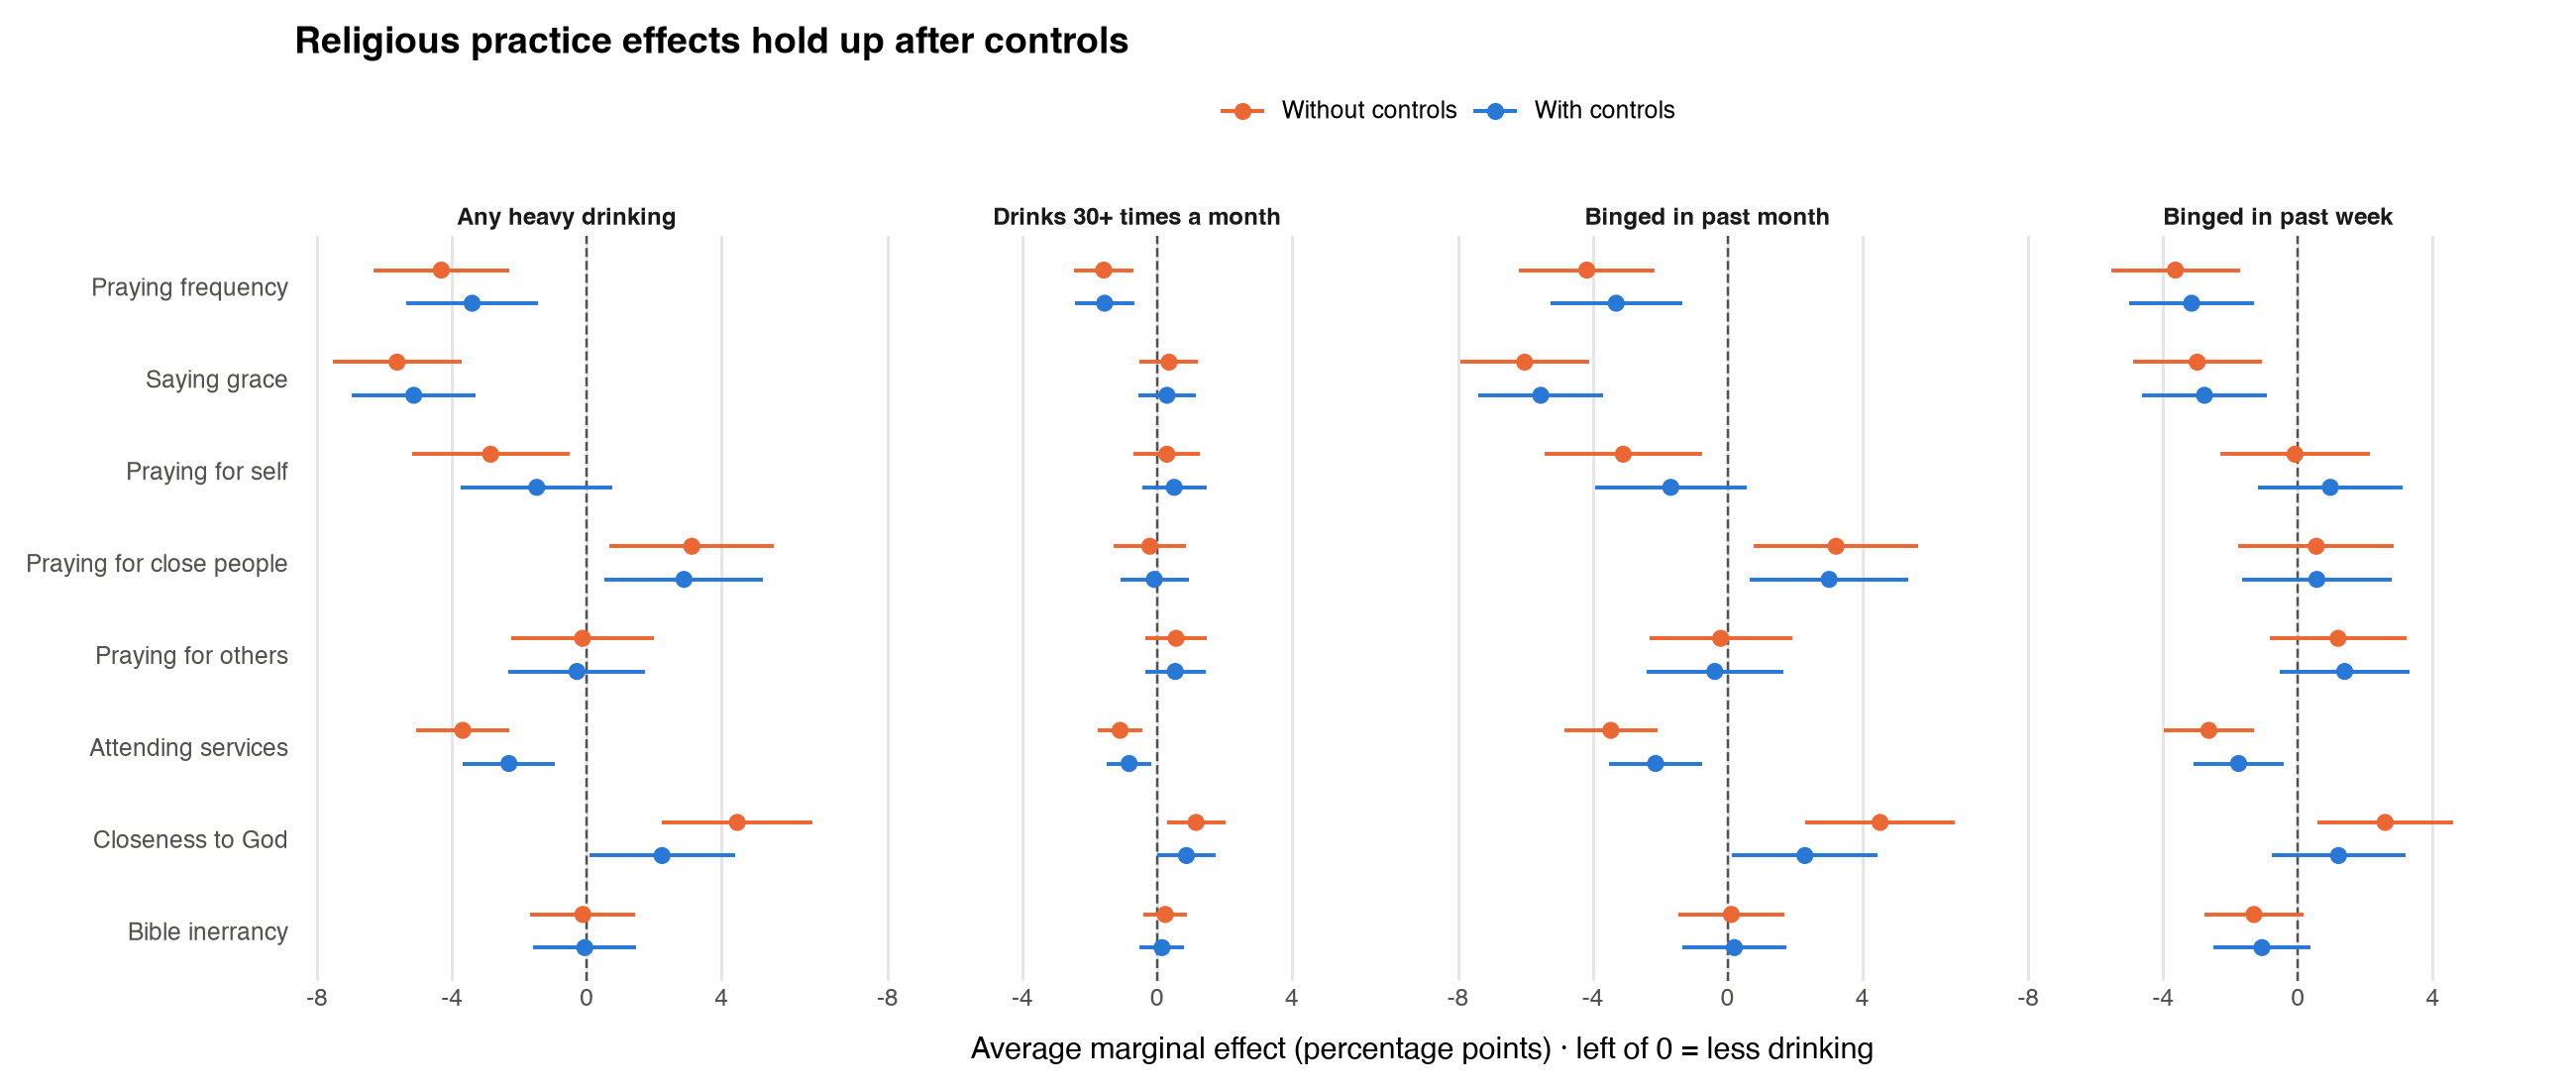

In [38]:
# Average marginal effects (percentage points) for the 8 religion items, without vs with controls
rows = []
for o, i in zip(outcomes, range(0, 8, 2)):
    for version, m in [("Without controls", pairs[i]), ("With controls", pairs[i + 1])]:
        me = m.get_margeff(at="overall").summary_frame()
        for v in practices + beliefs:
            rows.append({"outcome": outcome_labels[o], "item": item_labels[v], "version": version,
                         "AME": me.loc[v, "dy/dx"] * 100,
                         "lo": me.loc[v, "Conf. Int. Low"] * 100, "hi": me.loc[v, "Cont. Int. Hi."] * 100})
cmp = pd.DataFrame(rows)
cmp["outcome"] = pd.Categorical(cmp["outcome"], categories=list(outcome_labels.values()))
item_order = [item_labels[v] for v in practices + beliefs][::-1]           # top to bottom as in the tables
cmp["y"] = cmp["item"].map({lab: i for i, lab in enumerate(item_order)})
cmp["y"] += np.where(cmp["version"] == "Without controls", 0.18, -0.18)     # nudge the two versions apart
cmp["version"] = pd.Categorical(cmp["version"], categories=["Without controls", "With controls"])

chart_cmp = (p9.ggplot(cmp, p9.aes(x="AME", y="y", color="version"))
             + p9.geom_vline(xintercept=0, color=MUTED, linetype="dashed")
             + p9.geom_segment(p9.aes(x="lo", xend="hi", yend="y"), size=0.8)
             + p9.geom_point(size=2.5)
             + p9.facet_wrap("~outcome", ncol=4)
             + p9.scale_y_continuous(breaks=list(range(len(item_order))), labels=item_order)
             + p9.scale_color_manual(values={"Without controls": ORANGE, "With controls": BLUE})
             + p9.labs(title="Religious practice effects hold up after controls",
                       x="Average marginal effect (percentage points) · left of 0 = less drinking", y="", color="")
             + base_theme + p9.theme(legend_position="top", figure_size=(13, 5.5),
                                     strip_text=p9.element_text(weight="bold", ha="center")))
chart_cmp